# Homework 5 - Acute Inflammations + Communities and Crime

**Name:** Yizhou Lu

**GitHub Username:** RussCTGL


## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
df = pd.read_csv("../data/diagnosis.data",
                 sep="\t",           # Columns are separated by tabs
                 encoding="utf-16",  # Read the file using UTF-16
                 decimal=",",        # Temperature uses a decimal comma
                 header=None)        # The file has no column names

df = df.replace({"yes": 1, "no": 0})  # Convert yes/no to 1/0

X = df.iloc[:, :6]              # First six columns are features
Y = df.iloc[:, 6:].astype(int)  # Last two columns are integer labels

print(X.shape)
print(Y.shape)

df.head()

(120, 6)
(120, 2)


,0,1,2,3,4,5,6,7
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

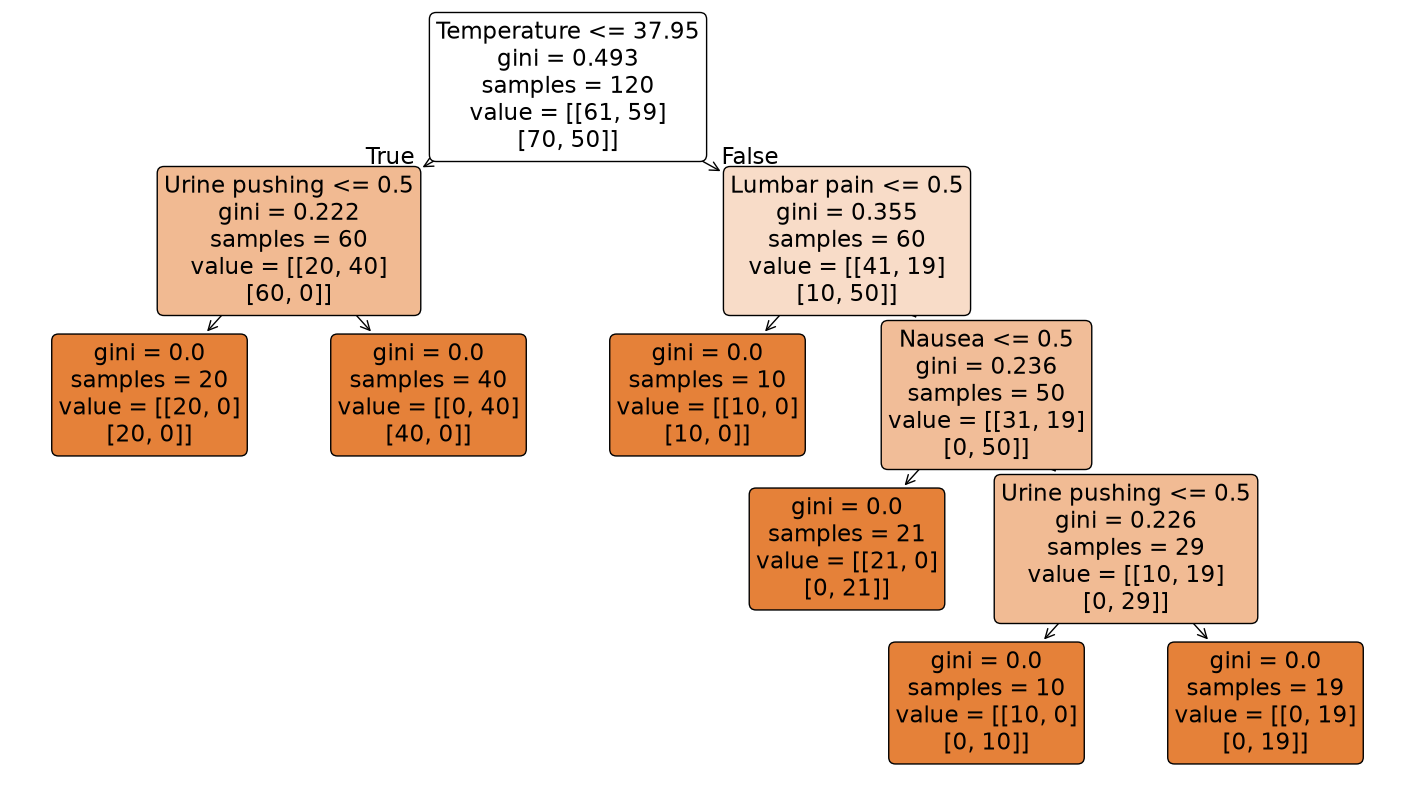

In [3]:
model = DecisionTreeClassifier(random_state=42)  # Make the result reproducible
model.fit(X, Y)  # Train the tree using all the data

feature_names = [
    "Temperature", "Nausea", "Lumbar pain",
    "Urine pushing", "Micturition pain", "Urethra burning"
]

plt.figure(figsize=(18, 10))  # Set the figure size
plot_tree(model, feature_names=feature_names, filled=True, rounded=True)
plt.show()

### (c) Convert the decision rules

Here, 1 means there exists disease, and 0 means it is absent.
The outputs are (bladder inflammation, nephritis).

1. IF Temperature <= 37.95 AND Urine pushing = 0,
   THEN predict (0, 0).

2. IF Temperature <= 37.95 AND Urine pushing = 1,
   THEN predict (1, 0).

3. IF Temperature > 37.95 AND Lumbar pain = 0,
   THEN predict (0, 0).

4. IF Temperature > 37.95 AND Lumbar pain = 1 AND Nausea = 0,
   THEN predict (0, 1).

5. IF Temperature > 37.95 AND Lumbar pain = 1 AND Nausea = 1
   AND Urine pushing = 0,
   THEN predict (0, 1).

6. IF Temperature > 37.95 AND Lumbar pain = 1 AND Nausea = 1
   AND Urine pushing = 1,
   THEN predict (1, 1).

### (d) Cost-complexity pruning

In [4]:
path = model.cost_complexity_pruning_path(X, Y)  # Get candidate alpha values

# Compare the size and training accuracy of each tree
for alpha in path.ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    tree.fit(X, Y)

    print("Alpha:", round(alpha, 4),
          "Leaves:", tree.get_n_leaves(),
          "Depth:", tree.get_depth(),
          "Training accuracy:", round(tree.score(X, Y), 4))

Alpha: 0.0 Leaves: 6 Depth: 4 Training accuracy: 1.0
Alpha: 0.0491 Leaves: 4 Depth: 2 Training accuracy: 0.8417
Alpha: 0.0795 Leaves: 3 Depth: 2 Training accuracy: 0.7583
Alpha: 0.1111 Leaves: 2 Depth: 1 Training accuracy: 0.5917
Alpha: 0.2042 Leaves: 1 Depth: 0 Training accuracy: 0.25


Leaves: 4
Depth: 2
Training accuracy: 0.8416666666666667


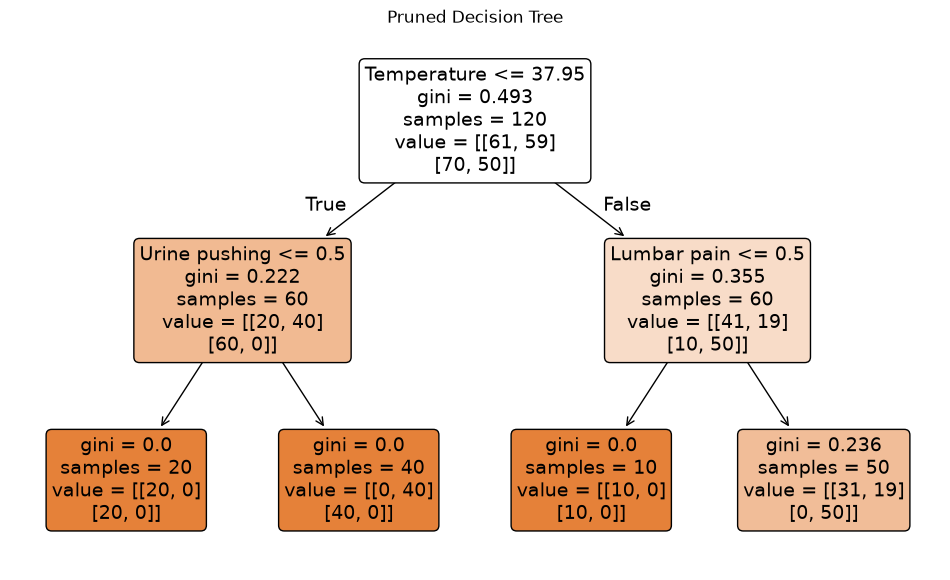

In [5]:
pruned_model = DecisionTreeClassifier(random_state=42, ccp_alpha=0.05)
pruned_model.fit(X, Y)  # Fit the selected pruned tree

print("Leaves:", pruned_model.get_n_leaves())
print("Depth:", pruned_model.get_depth())
print("Training accuracy:", pruned_model.score(X, Y))

plt.figure(figsize=(12, 7))
plot_tree(pruned_model, feature_names=feature_names,
          filled=True, rounded=True)
plt.title("Pruned Decision Tree")
plt.show()

I chose alpha = 0.05 for pruning. The tree had 4 leaves and a depth of 2. Before pruning we had 6 leaves and a depth of 4. I obtained shorter rules, but the training accuracy dropped from 100% to 84.17%. A prediction counts as correct only if both disease labels are correct.

The outputs are (bladder inflammation, nephritis).
Here, 1 means the disease is present, and 0 means it is absent.

1. IF Temperature <= 37.95 AND Urine pushing = 0,
   THEN predict (0, 0).

2. IF Temperature <= 37.95 AND Urine pushing = 1,
   THEN predict (1, 0).

3. IF Temperature > 37.95 AND Lumbar pain = 0,
   THEN predict (0, 0).

4. IF Temperature > 37.95 AND Lumbar pain = 1,
   THEN predict (0, 1).

I also noticed that all 19 errors came from patients with both diseases. The pruned tree predicted (0, 1) for these patients instead of (1, 1). Although the rules became shorter, pruning removed the tree’s ability to identify both diseases together.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
columns = []
with open("../data/communities.names") as file:
    for line in file:
        if line.startswith("@attribute"):
            parts = line.split()  # Split the line into words
            column_name = parts[1]  # Get the second word
            columns.append(column_name)  # Add it to the list

df = pd.read_csv("../data/communities.data",
                 names=columns, na_values="?")

train = df.iloc[:1495]  # First 1495 rows for training
test = df.iloc[1495:]   # Remaining rows for testing

print(train.shape)
print(test.shape)

(1495, 128)
(499, 128)


### (b) Missing values

In [7]:
drop_columns = ["state", "county", "community", "communityname", "fold"]

train = train.drop(columns=drop_columns)  # Remove nonpredictive columns
test = test.drop(columns=drop_columns)

X_train = train.drop(columns="ViolentCrimesPerPop")  # Separate features and target
Y_train = train["ViolentCrimesPerPop"]

X_test = test.drop(columns="ViolentCrimesPerPop")
Y_test = test["ViolentCrimesPerPop"]

means = X_train.mean()  # Calculate means using only the training data
X_train = X_train.fillna(means)  # Fill missing training values
X_test = X_test.fillna(means)    # Use the same means for the test data

print(X_train.isna().sum().sum())  # Check remaining missing values
print(X_test.isna().sum().sum())

0
0


### (c) Plot a correlation matrix

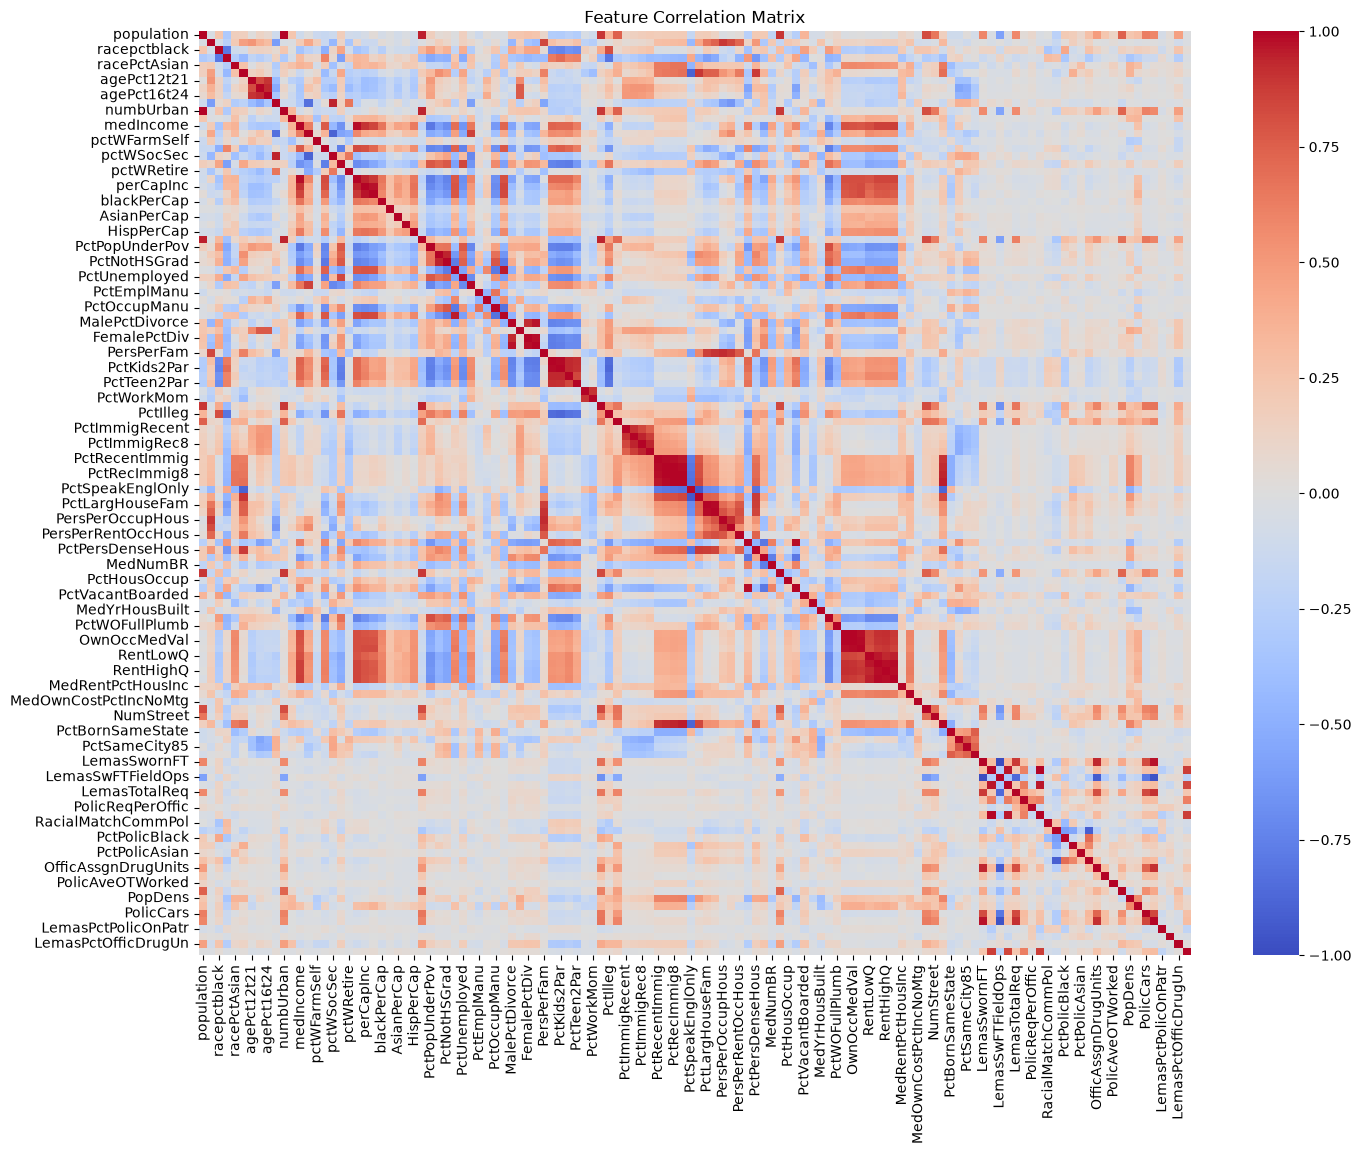

In [8]:
plt.figure(figsize=(16, 12))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
cv = X_train.std(ddof=1) / X_train.mean()  # Sample standard deviation divided by mean
print(cv.to_string())  # Show the CV for every feature

population               2.241105
householdsize            0.355800
racepctblack             1.428885
racePctWhite             0.330213
racePctAsian             1.359100
racePctHisp              1.612091
agePct12t21              0.369083
agePct12t29              0.291315
agePct16t24              0.500310
agePct65up               0.412776
numbUrban                2.038461
pctUrban                 0.643318
medIncome                0.591978
pctWWage                 0.328614
pctWFarmSelf             0.701898
pctWInvInc               0.365335
pctWSocSec               0.360715
pctWPubAsst              0.706206
pctWRetire               0.345421
medFamInc                0.540670
perCapInc                0.558079
whitePerCap              0.519828
blackPerCap              0.599341
indianPerCap             0.818368
AsianPerCap              0.614866
OtherPerCap              0.673222
HispPerCap               0.484068
NumUnderPov              2.342443
PctPopUnderPov           0.754470
PctLess9thGrad

### (e) Scatter plots and box plots for highest CV features

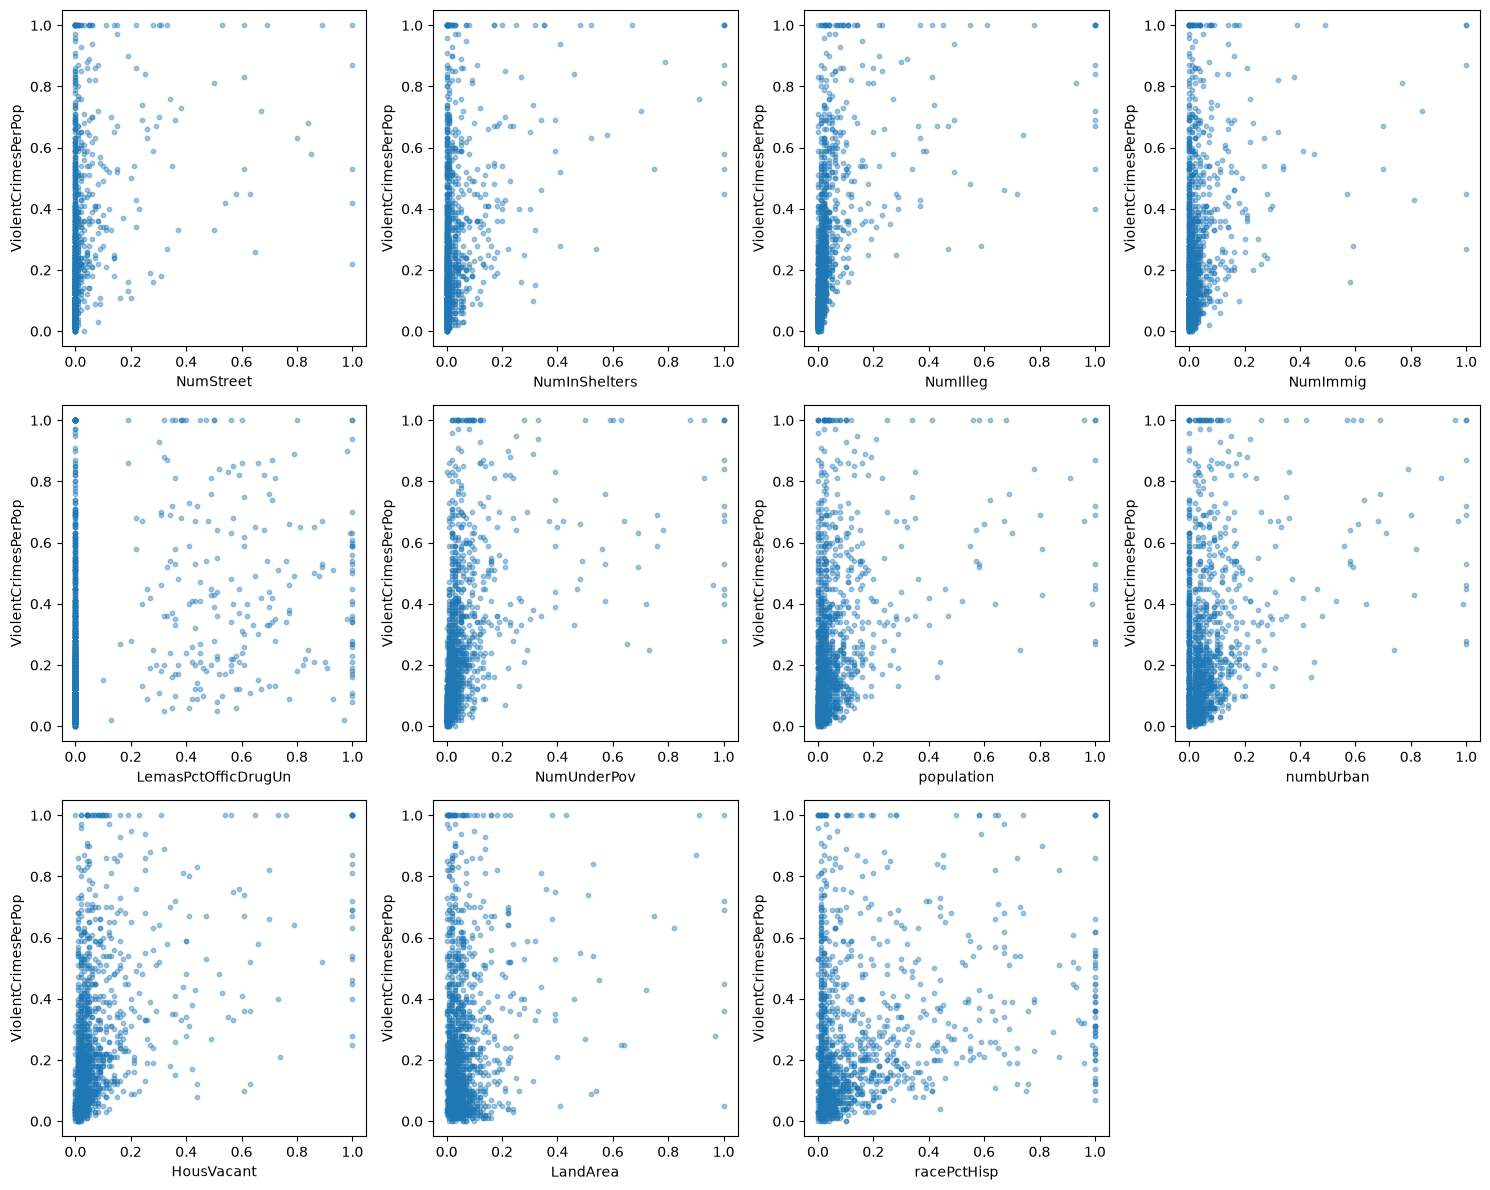

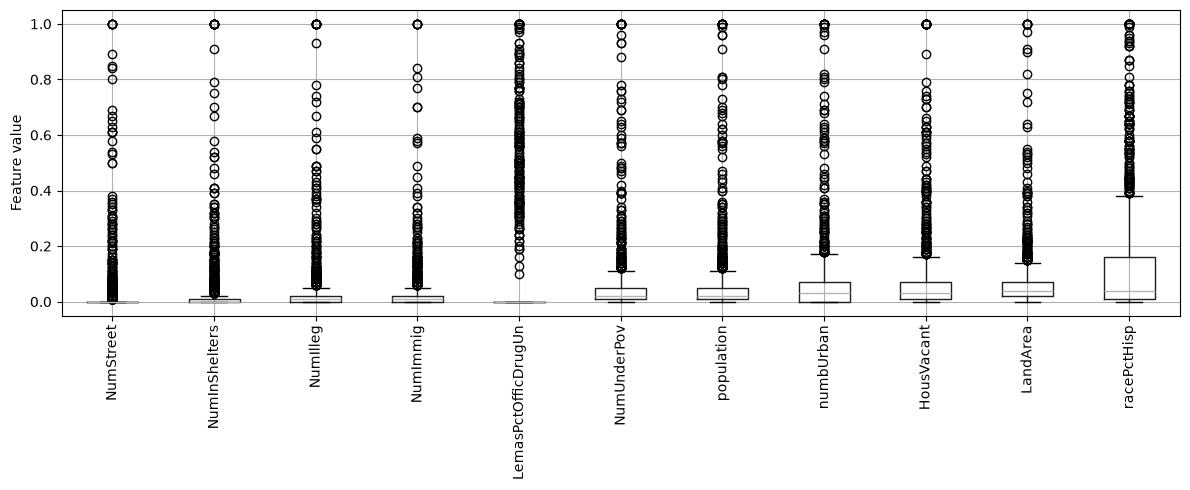

In [10]:
top_features = cv.nlargest(11).index  # Select the 11 features with the highest CV

plt.figure(figsize=(15, 12))

for i, feature in enumerate(top_features):
    plt.subplot(3, 4, i + 1)  # Place each scatter plot in the grid
    plt.scatter(X_train[feature], Y_train, s=10, alpha=0.4)
    plt.xlabel(feature)
    plt.ylabel("ViolentCrimesPerPop")

plt.tight_layout()
plt.show()

X_train[top_features].boxplot(figsize=(12, 5), rot=90)  # Plot the feature distributions
plt.ylabel("Feature value")
plt.tight_layout()
plt.show()

I selected the 11 features with the highest CV values because ⌊√128⌋ = 11. From the scatter plots, I can have a general idea of possible relationships between these features and the target, but I can't determine whether they are statistically significant. Statistical tests are needed to assess that. Also, high CV values do not directly mean these features are the most useful for predicting crime rates.

### (f) Fit a linear model

In [11]:
linear = LinearRegression()
linear.fit(X_train, Y_train)  # Fit the model using all features

Y_pred = linear.predict(X_test)  # Predict the test targets
linear_mse = mean_squared_error(Y_test, Y_pred)  # Calculate the test MSE

print("Linear regression test MSE:", linear_mse)

Linear regression test MSE: 0.018141971135530104


### (g) Fit a ridge regression model

In [12]:
ridge_model = make_pipeline(
    SimpleImputer(strategy="mean"),  # Fill missing values within each fold
    StandardScaler(),               # Standardize the features
    Ridge()
)

ridge_parameters = {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}

ridge = GridSearchCV(ridge_model, ridge_parameters, cv=5,
                     scoring="neg_mean_squared_error")

X_train_raw = train.drop(columns="ViolentCrimesPerPop") # Remove the target column to keep only the input features
X_test_raw = test.drop(columns="ViolentCrimesPerPop")

ridge.fit(X_train_raw, Y_train)
Y_pred = ridge.predict(X_test_raw)

ridge_mse = mean_squared_error(Y_test, Y_pred)

print("Best lambda:", ridge.best_params_["ridge__alpha"])
print("Ridge test MSE:", ridge_mse)

Best lambda: 100
Ridge test MSE: 0.01750781443449286


### (h) Fit a LASSO model

In [13]:
# Lambda values to try
lasso_parameters = {
    "lasso__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1]
}

# Build LASSO without standardization
lasso_model = make_pipeline(
    SimpleImputer(strategy="mean"),
    Lasso(max_iter=100000)
)

# Select lambda using 5-fold cross-validation
lasso = GridSearchCV(
    lasso_model,
    lasso_parameters,
    cv=5,
    scoring="neg_mean_squared_error"
)
lasso.fit(X_train_raw, Y_train)

# Predict and calculate the test error
lasso_predictions = lasso.predict(X_test_raw)
lasso_mse = mean_squared_error(Y_test, lasso_predictions)

# Find variables with nonzero coefficients
best_pipeline = lasso.best_estimator_  # Get the best fitted pipeline
best_lasso = best_pipeline.named_steps["lasso"]  # Get the LASSO model
lasso_coefficients = best_lasso.coef_  # Get the coefficients
regression_features = X_train_raw.columns  # Get the feature names
selected = lasso_coefficients != 0  # Check which coefficients are nonzero
lasso_variables = regression_features[selected]  # Select the corresponding names

print("LASSO without standardization")
print("Best lambda:", lasso.best_params_["lasso__alpha"])
print("Test MSE:", lasso_mse)
print("Selected variables:", lasso_variables.tolist())

LASSO without standardization
Best lambda: 0.0001
Test MSE: 0.017786089519102134
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIn

In [14]:
# Build LASSO with standardization
scaled_lasso_model = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    Lasso(max_iter=100000)
)

# Select lambda using 5-fold cross-validation
scaled_lasso = GridSearchCV(
    scaled_lasso_model,
    lasso_parameters,
    cv=5,
    scoring="neg_mean_squared_error"
)
scaled_lasso.fit(X_train_raw, Y_train)

# Predict and calculate the test error
scaled_lasso_predictions = scaled_lasso.predict(X_test_raw)
scaled_lasso_mse = mean_squared_error(Y_test, scaled_lasso_predictions)

# Find variables with nonzero coefficients
best_scaled_pipeline = scaled_lasso.best_estimator_
best_scaled_lasso = best_scaled_pipeline.named_steps["lasso"]
scaled_coefficients = best_scaled_lasso.coef_

regression_features = X_train_raw.columns
scaled_selected = scaled_coefficients != 0
scaled_variables = regression_features[scaled_selected]

print("LASSO with standardization")
print("Best lambda:", scaled_lasso.best_params_["lasso__alpha"])
print("Test MSE:", scaled_lasso_mse)
print("Selected variables:", scaled_variables.tolist())

LASSO with standardization
Best lambda: 0.001
Test MSE: 0.01775814926021371
Selected variables: ['racepctblack', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwFTFieldPerPop', 'LemasTotalReq', 'PolicReqPerOffic', 

I obtained a test MSE of 0.017786 without standardization and 0.017758 with standardization. Standardization slightly reduced the test error. The standardized model selected 68 variables, while 78 were selected without standardization. In this case, the standardized model used fewer variables and got a slightly lower test MSE.

### (i) Fit a PCR model

In [15]:
# Build the PCR model
pcr_model = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    PCA(svd_solver="full"),
    LinearRegression()
)

# Try every possible number of components
pcr_parameters = {
    "pca__n_components": list(range(1, X_train_raw.shape[1] + 1))
}

# Select M using 5-fold cross-validation
pcr = GridSearchCV(
    pcr_model,                         # The model to train
    pcr_parameters,                        # Parameter values to try
    cv=5,                              # Use 5-fold cross-validation
    scoring="neg_mean_squared_error"   # Select based on prediction error
)
pcr.fit(X_train_raw, Y_train)

# Predict and calculate the test error
pcr_predictions = pcr.predict(X_test_raw)
pcr_mse = mean_squared_error(Y_test, pcr_predictions)

print("Best M:", pcr.best_params_["pca__n_components"])
print("PCR test MSE:", pcr_mse)

Best M: 95
PCR test MSE: 0.018392931230387776


### (j) Fit a boosting tree

In [16]:
# Build the XGBoost model
boost_model = make_pipeline(
    SimpleImputer(strategy="mean"),
    XGBRegressor(random_state=42)
)

# Alpha values to try
boost_parameters = {
    "xgbregressor__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]
}

# Select alpha using 5-fold cross-validation
boost = GridSearchCV(
    boost_model,
    boost_parameters,
    cv=5,
    scoring="neg_mean_squared_error"
)
boost.fit(X_train_raw, Y_train)

# Predict and calculate the test error
boost_predictions = boost.predict(X_test_raw)
boost_mse = mean_squared_error(Y_test, boost_predictions)

print("Best alpha:", boost.best_params_["xgbregressor__reg_alpha"])
print("XGBoost test MSE:", boost_mse)

Best alpha: 1
XGBoost test MSE: 0.017747461401957192


## References

"API Reference." *pandas Documentation*, version 3.1.0, pandas development team, pandas.pydata.org/docs/reference/. Accessed 30 Oct. 2026.

"API Reference." *scikit-learn Documentation*, version 1.9.1, scikit-learn developers, scikit-learn.org/stable/api/. Accessed 30 Oct. 2026.

Czerniak, Jacek. "Acute Inflammations." *UCI Machine Learning Repository*, 2003, doi:10.24432/C5V59S. Accessed 30 Oct. 2026.

James, Gareth, et al. *An Introduction to Statistical Learning: With Applications in Python*. Springer, 2023, doi:10.1007/978-3-031-38747-0.

"matplotlib.pyplot." *Matplotlib Documentation*, version 3.11.2, Matplotlib Development Team, matplotlib.org/stable/api/pyplot_summary.html. Accessed 30 Oct. 2026.

Mayo, Matthew. "Simplifying Decision Tree Interpretability with Python & Scikit-learn." *KDnuggets*, May 2017, www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html. Accessed 30 Oct. 2026.

"Python API Reference." *XGBoost Documentation*, version 3.4.1, xgboost developers, xgboost.readthedocs.io/en/stable/python/python_api.html. Accessed 30 Oct. 2026.

Rajati, Mohammad Reza. "Linear Model Selection and Regularization." DSCI 552: Machine Learning for Data Science, Fall 2026, University of Southern California. Lecture slides.

Rajati, Mohammad Reza. "Linear Regression." DSCI 552: Machine Learning for Data Science, Fall 2026, University of Southern California. Lecture slides.

Rajati, Mohammad Reza. "Resampling Methods." DSCI 552: Machine Learning for Data Science, Fall 2026, University of Southern California. Lecture slides.

Rajati, Mohammad Reza. "Tree-Based Methods." DSCI 552: Machine Learning for Data Science, Fall 2026, University of Southern California. Lecture slides.

Redmond, Michael. "Communities and Crime." *UCI Machine Learning Repository*, 2002, doi:10.24432/C53W3X. Accessed 30 Oct. 2026.

"seaborn.heatmap." *seaborn Documentation*, version 0.13.2, seaborn.pydata.org/generated/seaborn.heatmap.html. Accessed 30 Oct. 2026.

## AI Assistance Disclosure and Prompts

**Setup and study planning (whole assignment)**

- **Tool:** Claude Code (Anthropic), model Claude Opus 5.5, 29 Oct. 2026
- **Actual prompt:** "setup hw5 folder"
- **What the AI provided:** local folder and Python environment, copy of the raw data, this blank notebook, a study guide PDF (steps and reading list), and generic example code on synthetic data (not the homework data).
- **How I used it:** set up a clean work folder to work on
- **MLA citation:** "Setup and study guide for DSCI 552 Homework 5" prompt. *Claude Code*, Claude Opus 5.5 version, Anthropic, 29 Oct. 2026


**Encoding class labels as integers (data preprocessing)**

- **Tool:** Claude Code (Anthropic), model Claude Opus 5.5, 30 Oct. 2026
- **Actual prompt:** "how to change data labels to integers?"
- **What the AI provided:** general pandas/scikit-learn options for turning string class labels into integers (`Series.map` with a dictionary, `LabelEncoder`, `astype("category").cat.codes` / `pd.factorize`). df.iloc[:, 6:] keeps both target columns as a DataFrame.
- **How I used it:** I picked .astype(int) method and integrate it into the code.
- **MLA citation:** "How to change data labels to integers" prompt. *Claude Code*, Claude Opus 5.5 version, Anthropic, 30 Oct. 2026

**Cost-complexity pruning in scikit-learn (Problem 1(d))**

- **Tool:** Claude Code (Anthropic), model Claude Opus 5.5, 30 Oct. 2026
- **Actual prompt:** "how to use pruning in sklearn"
- **What the AI provided:** a general explanation of pre-pruning (`max_depth`, `min_samples_leaf`) versus cost-complexity post-pruning (`ccp_alpha`), and the workflow `cost_complexity_pruning_path` → fit one tree per alpha → choose alpha by cross-validation. It included a demo on synthetic `make_classification` data (not the homework data), and noted that `export_text` shows only the first output for multi-label targets.
- **How I used it:** I used `cost_complexity_pruning_path` to list the candidate alphas for my tree, compared leaves/depth/accuracy myself, and chose alpha = 0.05.
- **MLA citation:** "How to use pruning in sklearn" prompt. *Claude Code*, Claude Opus 5.5 version, Anthropic, 30 Oct. 2026

**Extracting nonzero LASSO coefficients from a GridSearchCV pipeline (Problem 2(h))**

- **Tool:** Claude Code (Anthropic), model Claude Opus 5.5, 30 Oct. 2026
- **Actual prompt:** "I used make_pipeline and GridSearchCV to fit a LASSO model and select alpha. How can I get the coefficients of the best model and list the feature names with nonzero coefficients? My feature names are in X_train_raw.columns. Please use simple code and explain each step."
- **What the AI provided:** a step-by-step explanation of `best_estimator_` → `named_steps["lasso"]` → `coef_` → boolean mask `coef_ != 0` on `X_train_raw.columns`, an optional sorted `pd.Series` of the nonzero coefficients, and a note that `SimpleImputer` drops all-missing columns, which would break the name/coefficient alignment.
- **How I used it:** I used the explanation to figure out how to achieve my goal with correct code. I integrated it into my work after understanding the samples.
- **MLA citation:** "How to get nonzero LASSO coefficients from a GridSearchCV pipeline" prompt. *Claude Code*, Claude Opus 5.5 version, Anthropic, 30 Oct. 2026